# 03 · 权重拟合 Fitting the scoring weights

**Data Science Club · BIPH FindMy**

匹配引擎为每一对（丢失描述，捡到描述）算出 9 个"证据特征"，每个特征乘以一个权重后相加，再经过 sigmoid 变成概率：

$$P(\text{same object}) = \sigma\Big(b + \sum_i w_i x_i\Big)$$

这就是**逻辑回归**。这个 notebook 走一遍我们是怎么从数据里学到这些权重 $w_i$ 的，以及怎么定"强匹配 / 可能匹配"的分界线。

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "matcher").is_dir():  # works from the repo root or from matcher/notebooks
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

INDIGO, CYAN, MUTED, INK, ORANGE = "#3b3fb6", "#2bb5c4", "#9aa0b4", "#1d1f2e", "#c2410c"
plt.rcParams.update({
    "font.family": ["Noto Sans CJK SC", "DejaVu Sans"],  # Chinese labels need a CJK font
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
})
pd.set_option("display.max_colwidth", 70)

## 1. 训练数据：每一对描述都是一行 · Every pair is a row

训练用另一个独立的虚拟校园（种子 7，900 件物品），按物品分成 train 60% / val 20% / test 20%，测试集在拟合时完全不碰。

In [2]:
from matcher.api import Matcher
from matcher.eval.common import fit_logistic, pair_table, prepare
from matcher.eval.fit_weights import N_OBJECTS, SEED, fit_backend
from matcher.eval.generate import generate
from matcher.features import FEATURES
from matcher.scoring import sigmoid

data = generate(N_OBJECTS, seed=SEED)
weights = fit_backend("onnx", data)        # exactly what produced matcher/data/weights.json

m = Matcher(backend="onnx")
m.weights = weights
truth = {q.id: f.id for q in data.reports("lost") for f in data.reports("found") if q.object_id == f.object_id}
def table_for(split):
    return pair_table(m, prepare(m, data.reports("lost", split)), prepare(m, data.reports("found", split)), truth)
train, val = table_for("train"), table_for("val")
print(f"train pairs: {len(train.y):,} ({int(train.y.sum())} true matches = {100 * train.y.mean():.2f}%)")
print(f"val pairs:   {len(val.y):,} ({int(val.y.sum())} true matches)")

[onnx] pairs train=95651 (pos 290), val=11984
[onnx] bias=-10.92 text=3.32 detail=0.89 marks=0.98 code=2.97 category=2.73 color=1.93 brand=1.40 location=1.91 time=5.32
[onnx] centers={'text': 0.30675479769706726, 'detail': 0.3063485026359558} thresholds={'strong': 0.7, 'possible': 0.15}


train pairs: 95,651 (290 true matches = 0.30%)
val pairs:   11,984 (103 true matches)


真匹配只占不到 1%，这很正常：一个失主只对应一件捡到的物品，其他几百件都是错的。

先看看每个特征在"真匹配"和"不是同一件"两组里的平均值。差得越多的特征，区分能力越强：

,different objects,same object
text,0.004,0.253
detail,0.013,0.110
marks,0.029,0.340
code,-0.014,0.155
category,-0.701,0.846
color,-0.450,0.688
brand,-0.040,0.114
location,-0.186,0.524
time,0.442,0.825


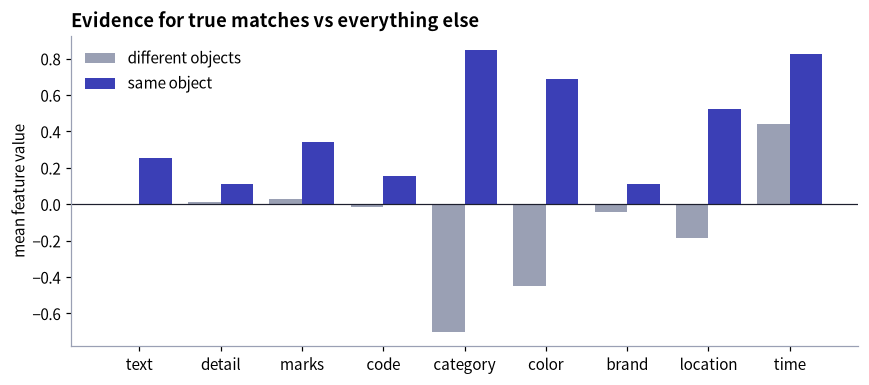

In [3]:
df = pd.DataFrame(train.X, columns=FEATURES)
df["same object"] = train.y.astype(bool)
means = df.groupby("same object")[FEATURES].mean().T
means.columns = ["different objects", "same object"]
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(FEATURES))
ax.bar(x - 0.2, means["different objects"], 0.4, color=MUTED, label="different objects")
ax.bar(x + 0.2, means["same object"], 0.4, color=INDIGO, label="same object")
ax.set_xticks(x, FEATURES)
ax.axhline(0, color=INK, linewidth=0.8)
ax.set_ylabel("mean feature value")
ax.legend(frameon=False)
ax.set_title("Evidence for true matches vs everything else", loc="left", fontweight="bold")
fig.tight_layout()
means.round(3)

## 2. 为什么限制权重 ≥ 0 · Why constrain the weights to be non-negative?

我们要求每个权重都 ≥ 0，意思是**多一条吻合的证据，分数永远不会降**。这样学出来的模型更好解释，也不会学到奇怪的规律（比如"颜色一致反而扣分"）。
下面对比加限制和不加限制的拟合结果：

,unconstrained,w ≥ 0 (used)
text,3.33,3.32
detail,0.81,0.89
marks,0.97,0.98
code,2.96,2.97
category,2.71,2.73
color,1.90,1.93
brand,1.33,1.40
location,1.90,1.91
time,5.30,5.32


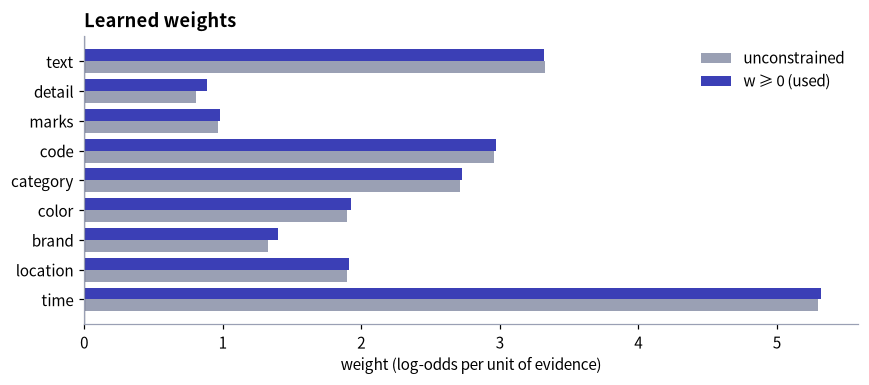

In [4]:
b_free, w_free = fit_logistic(train.X, train.y, nonneg=False)
b_pos, w_pos = fit_logistic(train.X, train.y, nonneg=True)
cmp = pd.DataFrame({"unconstrained": w_free, "w ≥ 0 (used)": w_pos}, index=FEATURES).round(2)

fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(FEATURES))
ax.barh(y + 0.2, cmp["unconstrained"], 0.4, color=MUTED, label="unconstrained")
ax.barh(y - 0.2, cmp["w ≥ 0 (used)"], 0.4, color=INDIGO, label="w ≥ 0 (used)")
ax.set_yticks(y, FEATURES)
ax.invert_yaxis()
ax.axvline(0, color=INK, linewidth=0.8)
ax.set_xlabel("weight (log-odds per unit of evidence)")
ax.legend(frameon=False)
ax.set_title("Learned weights", loc="left", fontweight="bold")
fig.tight_layout()
cmp

## 3. 概率准不准：校准曲线 · Calibration

模型说"80% 是同一件"的时候，在验证集上真的有大约 80% 是同一件吗？把预测概率分组，和实际比例对比：

Brier score on validation pairs: 0.0034 (lower is better)


,bin,pairs,mean predicted,actually same object
0,0.00–0.02,11780,0.000,0.000
1,0.02–0.05,57,0.031,0.140
2,0.05–0.10,32,0.072,0.188
3,0.10–0.20,30,0.139,0.333
4,0.20–0.40,26,0.288,0.615
5,0.40–0.60,17,0.478,1.000
6,0.60–0.80,16,0.699,0.938
7,0.80–0.90,11,0.846,1.000
8,0.90–1.00,15,0.957,1.000


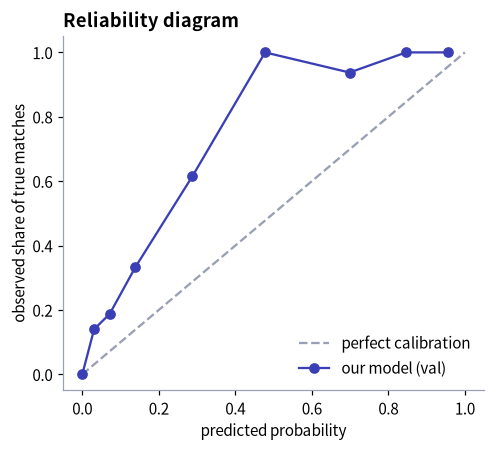

In [5]:
w = np.array([weights.weights[f] for f in FEATURES])
p_val = np.array([sigmoid(weights.bias + float(x @ w)) for x in val.X])
edges = np.array([0, 0.02, 0.05, 0.1, 0.2, 0.4, 0.6, 0.8, 0.9, 1.0])
which = np.clip(np.digitize(p_val, edges) - 1, 0, len(edges) - 2)
rows = []
for k in range(len(edges) - 1):
    sel = which == k
    if sel.sum():
        rows.append({"bin": f"{edges[k]:.2f}–{edges[k + 1]:.2f}", "pairs": int(sel.sum()),
                     "mean predicted": p_val[sel].mean(), "actually same object": val.y[sel].mean()})
cal = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([0, 1], [0, 1], "--", color=MUTED, label="perfect calibration")
ax.plot(cal["mean predicted"], cal["actually same object"], "o-", color=INDIGO, label="our model (val)")
ax.set_xlabel("predicted probability")
ax.set_ylabel("observed share of true matches")
ax.legend(frameon=False)
ax.set_title("Reliability diagram", loc="left", fontweight="bold")
fig.tight_layout()
brier = float(np.mean((p_val - val.y) ** 2))
print(f"Brier score on validation pairs: {brier:.4f} (lower is better)")
cal.round(3)

## 4. 怎么定"强匹配 / 可能匹配" · Choosing the bands

学生在网站上看到的不是具体概率，而是两档：

- **强匹配 strong**：要求**精确率**高。说是强匹配的，大多数真的就是。
- **可能匹配 possible**：要求**召回率**高。真正的那一件尽量不要漏掉，宁可多给几个让学生自己看照片确认。

阈值在验证集上选（`pick_thresholds`）：

strong   ≥ 0.70: precision 97%, recall 32%
possible ≥ 0.15: precision 82%, recall 76%


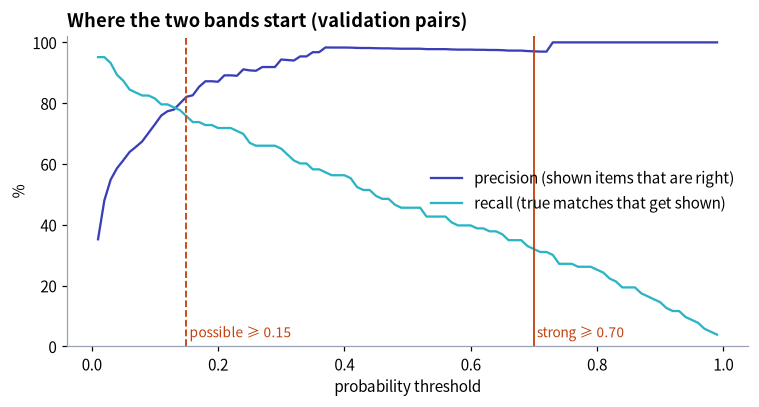

In [6]:
th = weights.thresholds
grid = np.linspace(0.01, 0.99, 99)
prec = [val.y[p_val >= t].mean() if (p_val >= t).any() else np.nan for t in grid]
rec = [val.y[p_val >= t].sum() / val.y.sum() for t in grid]

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(grid, np.array(prec) * 100, color=INDIGO, label="precision (shown items that are right)")
ax.plot(grid, np.array(rec) * 100, color=CYAN, label="recall (true matches that get shown)")
for name, t, style in (("strong", th["strong"], "-"), ("possible", th["possible"], "--")):
    ax.axvline(t, color=ORANGE, linestyle=style, linewidth=1.2)
    ax.text(t, 3, f" {name} ≥ {t:.2f}", color=ORANGE, fontsize=9)
ax.set_xlabel("probability threshold")
ax.set_ylabel("%")
ax.set_ylim(0, 102)
ax.legend(frameon=False, loc="center right")
ax.set_title("Where the two bands start (validation pairs)", loc="left", fontweight="bold")
fig.tight_layout()
for name in ("strong", "possible"):
    sel = p_val >= th[name]
    print(f"{name:8s} ≥ {th[name]:.2f}: precision {100 * val.y[sel].mean():.0f}%, "
          f"recall {100 * val.y[sel].sum() / val.y.sum():.0f}%")

## 5. 学到的权重 vs 手调的权重 · Fitted vs hand-set weights

项目一开始的权重是我们凭直觉手调的。下面在**从没用过的测试校园**（种子 2026）上比较两者：

In [7]:
from matcher.eval.common import metrics
from matcher.eval.run import Evaluator, synthetic_test

test_set, _ = synthetic_test(900)
ev = Evaluator(test_set)
pd.DataFrame({"hand-set weights": metrics(ev.model_ranks("onnx", manual=True)),
              "fitted weights": metrics(ev.model_ranks("onnx"))}).T[["n", "R@1", "R@3", "MRR"]].round(3)

,n,R@1,R@3,MRR
hand-set weights,97.0,0.856,0.99,0.924
fitted weights,97.0,0.887,0.99,0.938


## 6. 拆开一个匹配看 · Explaining one match

"六个黑色水杯"场景：失主用中文写"黑色保温杯，贴了恐龙贴纸"，系统要从 6 个黑色水杯里找出对的那一个。下图是每条证据给每个候选加了多少分（log-odds），这也是网站上"理由"标签的来源。

black thermos bottle with a dinosaur sticker, gym bleachers: 同类物品：水杯 +2.5 · 共同特征：贴纸、恐龙 +2.0 · 同一地点：体育馆 +1.9 · 颜色一致：黑色 +1.6
黑色水杯: 同类物品：水杯 +2.5 · 同一地点：体育馆 +1.9 · 颜色一致：黑色 +1.6 · 描述相似 +0.6


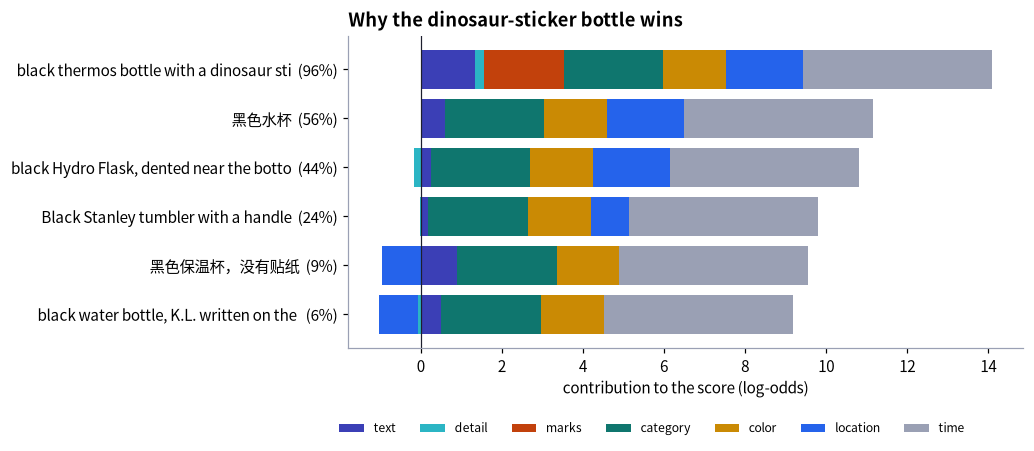

In [8]:
from datetime import datetime, timedelta, timezone
from matcher.api import ItemInput

live = Matcher(backend="onnx")              # the shipped weights from matcher/data/weights.json
now = datetime.now(timezone.utc).replace(microsecond=0)
lost = ItemInput("lost", "lost", "黑色保温杯 贴了恐龙贴纸，体育课后在体育馆丢的",
                 now - timedelta(days=2), now - timedelta(days=2, hours=-2), locations=["gym"])
cands = {
    "f1": "black thermos bottle with a dinosaur sticker, gym bleachers",
    "f2": "black Hydro Flask, dented near the bottom",
    "f3": "black water bottle, K.L. written on the lid",
    "f4": "Black Stanley tumbler with a handle",
    "f5": "黑色水杯",
    "f6": "黑色保温杯，没有贴纸",
}
places = {"f1": "gym", "f2": "gym", "f3": "cafeteria", "f4": "field_track", "f5": "gym", "f6": "library"}
found = [ItemInput(i, "found", t, now - timedelta(days=1), locations=[places[i]]) for i, t in cands.items()]
results = live.rank(lost, found, top_k=None, min_band="weak")

feats = [f for f in FEATURES if any(abs(r.contributions.get(f, 0)) > 1e-6 for r in results)]
fig, ax = plt.subplots(figsize=(9.5, 4.3))
left_pos = np.zeros(len(results))
left_neg = np.zeros(len(results))
palette = dict(zip(FEATURES, [INDIGO, CYAN, ORANGE, "#7c3aed", "#0f766e", "#ca8a04", "#be185d", "#2563eb", MUTED]))
labels = [f"{cands[r.candidate_id][:40]}  ({100 * r.probability:.0f}%)" for r in results]
for f in feats:
    vals = np.array([r.contributions.get(f, 0.0) for r in results])
    base = np.where(vals >= 0, left_pos, left_neg)
    ax.barh(range(len(results)), vals, left=base, color=palette[f], label=f)
    left_pos += np.clip(vals, 0, None)
    left_neg += np.clip(vals, None, 0)
ax.set_yticks(range(len(results)), labels)
ax.invert_yaxis()
ax.axvline(0, color=INK, linewidth=0.8)
ax.set_xlabel("contribution to the score (log-odds)")
ax.legend(frameon=False, ncol=len(feats), fontsize=8, loc="upper center", bbox_to_anchor=(0.45, -0.2))
ax.set_title("Why the dinosaur-sticker bottle wins", loc="left", fontweight="bold")
fig.tight_layout()
for r in results[:2]:
    print(f"{cands[r.candidate_id]}: " + " · ".join(f"{x['zh']} {x['contribution']:+.1f}" for x in r.reasons[:4]))

## 结论 · Takeaways

- **极度不平衡**：95,651 对训练样本里只有 290 对是真匹配（0.3%）。区分力最强的特征是类别、颜色、地点和特征标记。
- **≥ 0 的限制在这份数据上没起作用**：不加限制学出来的权重本来就全是正的，两种结果几乎一样。这个限制是一份保险：以后用真实数据重新拟合时，数据少、噪音大，有了它就不会学出"颜色一致反而扣分"这种反直觉的权重。
- **概率偏保守**：预测概率在 0.2–0.4 的那一组，实际有 63% 是真匹配；0.4 以上几乎全是。所以"可能匹配"的门槛可以定得比较低（0.15）：低分候选里，真匹配的比例其实不低。
- **两档的效果**（验证集，按配对统计）：强匹配 ≥ 0.70 时，精确率 97%、召回率 32%；可能匹配 ≥ 0.15 时，精确率 82%、召回率 76%。
- **学出来的权重更好**：在从没见过的测试校园上，R@1 从手调权重的 85.6% 提高到 88.7%。
- **理由能解释清楚**：恐龙贴纸水杯胜出，是因为它比其他黑色水杯多了一条"共同特征：贴纸、恐龙"（+2.0）。网站上的理由标签就是这么来的。另外，"没有贴纸"不会被当成有贴纸（否定词检测）。
- **下一步**：用社团采集的真实数据检查校准情况，偏差明显的话，可以加一层 isotonic 或 Platt 校准。